# Dyna-DQN — 같은 Neural Q·Optimizer·Target으로 Real과 Planning 학습

07의 Tabular Dyna-Q 다음 실습이다. Neural Q에는 Replay, Gradient Update와 Target Network가 필요하므로
별도 Notebook으로 구성한다. 기존 04–07의 셀·출력·메타데이터는 유지한다.

[실행 예제](../../examples/gridworld_dyna_dqn.py) · [구조 평가](../../docs/ARCHITECTURE.md#dyna-dqn-컴포넌트-조합-검증)

World Model은 기존 `TabularWorldModel`이다. Neural Network는 Q를 추정하며 환경모델까지 Neural일 필요는 없다.
이 실습은 결정적 환경의 **모델 생성 경험 학습 경로**를 검증한다. 모델의 일반화 성능을 주장하지 않는다.

## 1. 기존 컴포넌트와 예제 함수

라이브러리의 `DQNLearner` 하나를 두 경로에 전달한다. 알고리즘 계산은 예제 함수를 호출한다.
예제 namespace를 Notebook 위치에서 연결하며 `sys.path`와 설치된 패키지는 변경하지 않는다.
표준 MLP 128×128, Adam 1e-4, Huber, γ=.9, Batch 32, Warm-up 64, Replay 10,000을 사용한다.
ε는 실제 Step 2,000개에 걸쳐 1→.05로 감소하고 Target은 실제 Step 250개마다 동기화한다.

In [1]:
%matplotlib inline
import copy
import sys
import types
from importlib.machinery import ModuleSpec
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

example_dir = Path('../../examples').resolve()
if not (example_dir / 'gridworld_dyna_dqn.py').is_file():
    raise RuntimeError('Run this notebook from notebooks/dlfs4')
examples_package = types.ModuleType('examples')
examples_package.__path__ = [str(example_dir)]
examples_package.__spec__ = ModuleSpec('examples', loader=None, is_package=True)
examples_package.__spec__.submodule_search_locations = examples_package.__path__
sys.modules['examples'] = examples_package

from examples.gridworld_dyna_q import TabularWorldModel
from examples.gridworld_dyna_dqn import (
    create_learner, plan, synthetic_batch, comparison,
    make_n_step_experience, learn_real_n_step,
)
from modular_rl.data import Transition
from modular_rl.environment import make_dlfs4_gridworld_env
from plotting import plot_grid

SEEDS, STEPS = (7, 11, 19), 600
torch.manual_seed(7)
plt.close('all')

## 2. State ID는 저장하고 One-hot은 Model 입력에서 만든다

기존 InputAdapter는 정수 ID를 long으로 정규화한다. 기존 `nn.Embedding`에 단위행렬을 고정해
$\phi(s)=\operatorname{onehot}(s,S)$를 얻고 기존 `MLPRepresentation`에 연결한다.
Representation 전체는 Tensor→Tensor다. Replay와 World에는 원래 정수 ID를 저장한다.
Scalar/Batch의 앞쪽 차원, Model의 floating dtype와 device를 따른다.

In [2]:
demo = create_learner(n_states=3, n_actions=2, hidden_dims=(8,), dtype=torch.float64)
ids = torch.tensor([[0, 1], [2, 0]], dtype=torch.long)
encoded = demo.online_model.representation[0](ids)
print('IDs:', tuple(ids.shape), ids.dtype)
print('one-hot:', tuple(encoded.shape), encoded.dtype, encoded.device)
print('Q:', tuple(demo.online_model(ids).values.q[0].shape))
assert encoded.shape == (2, 2, 3)
assert not demo.online_model.representation[0].weight.requires_grad

IDs: (2, 2) torch.int64
one-hot: (2, 2, 3) torch.float64 cpu
Q: (2, 2, 2)


## 3. 같은 Target·Loss·Optimizer를 사용하는 두 학습 경로

Real은 Replay Batch, Planning은 World의 최신 예측 Batch를 같은 `learner.learn(batch)`에 전달한다.

$$Y=R+\gamma(1-\mathrm{terminated})\max_a Q_{\bar\theta}(S',a)$$

자연 종료는 Bootstrap하지 않고 Time-limit만 있으면 Bootstrap한다. `TDLossUpdateRule`에 미축약 Huber를 전달하고
기존 Learner가 mean·backward·Optimizer step을 수행한다. 다음은 Q Head를 상수로 만든 수치 검증이다.
Target=[4,6], Reward=1이므로 Target=6.4, Prediction=2의 signed TD Error=4.4, Huber Loss=3.9다.
Adam의 갱신을 Tabular의 고정 α 갱신과 동일하게 취급하지 않는다.

In [3]:
with torch.no_grad():
    for model, bias in [(demo.online_model, [0., 2.]), (demo.target_model, [4., 6.])]:
        model.estimator.network.weight.zero_()
        model.estimator.network.bias.copy_(torch.tensor(bias, dtype=torch.float64))
real = Transition(0, 1, 1., 2, False, False)
optimizer = demo.optimizer
real_result = demo.learn(real.to_batch())
world = TabularWorldModel()
world.observe(real)
planned = plan(world, demo, steps=1, batch_size=4, rng=np.random.default_rng(8))
print('Real TD Error / Loss:', real_result.td_error.tolist(), real_result.loss.item())
print('Planning updates:', planned['updates'])
print('Shared Adam step:', int(optimizer.state[demo.online_model.estimator.network.bias]['step']))
assert torch.allclose(real_result.td_error, torch.tensor([4.4], dtype=torch.float64))
assert np.isclose(real_result.loss.item(), 3.9)
assert demo.optimizer is optimizer
assert all(p.grad is None for p in demo.target_model.parameters())

Real TD Error / Loss: [4.4] 3.9000000000000004
Planning updates: 1
Shared Adam step: 2


## 4. Replay와 World Model은 다른 데이터 출처다

Replay는 실제 step 전이만 저장하고 과거 경험을 비복원 추출한다. World는 관측된 쌍마다 최신 예측을 보유하며
독립 NumPy RNG로 관측 쌍을 균등 추출한다. Planning Batch는 복원 추출이므로 관측 쌍 하나로 Batch 32도 가능하다.
World의 최신 결과 예측에서 생성한 전이이며 Replay를 꺼내 모델 예측이라고 부르지 않는다.

가상 전이는 다시 observe하거나 Real Replay에 넣지 않는다. World는 자연 종료를 보존하고 외부 Time-limit은 저장하지 않는다.
가상 전이의 log_prob은 None이다. 로그 확률이 있는 실제 경험과 같은 Replay에 섞지 않는다.

In [4]:
sampled = synthetic_batch(world, batch_size=32, rng=np.random.default_rng(9))
print('Synthetic observations:', sampled.observation.shape, sampled.observation.dtype)
print('Synthetic rewards:', sampled.reward.shape, sampled.reward.dtype)
print('flags / log_prob:', sampled.terminated.dtype, sampled.truncated.any().item(), sampled.log_prob)
assert sampled.observation.shape == (32,)
assert len(world) == 1

Synthetic observations: torch.Size([32]) torch.int64
Synthetic rewards: torch.Size([32]) torch.float32
flags / log_prob: torch.bool False None


## 5. 같은 실제 환경 Step 예산에서 비교

각 Seed에서 DQN, Dyna Planning=0/1/5, Real n=3/5 + Planning=1을 실행한다.
Seed가 같아도 Planning이 Network를 바꾸면 이후 경험은 달라진다.
아래는 빠른 600-Step 실습이며 CLI의 3,000-Step 실험 결과는 ARCHITECTURE.md에 별도로 기록한다.
성능 순위와 최적 정책 도달을 단일 Seed의 합격 조건으로 두지 않는다.

초기 Target copy는 1회이고 주기적 Sync Count와 구분한다. 이후 Sync는 실제 환경 Step 250,500,…에서
Real→observe→Planning 뒤 실행한다. Planning 증가가 Sync를 앞당기지 않는다.
실행시간은 CLI가 측정·출력하며 재실행 결과 비교를 위해 Notebook 출력·그래프에서는 제외한다.

In [5]:
results_7 = comparison(steps=STEPS, seeds=(7,))
print('seed 7:', [(r['n'], r['planning_steps'], r['environment_steps'],
                       r['real_updates'], r['planning_updates'], r['target_syncs']) for r in results_7])

seed 7: [(1, 0, 600, 537, 0, 2), (1, 0, 600, 537, 0, 2), (1, 1, 600, 537, 600, 2), (1, 5, 600, 537, 3000, 2), (3, 1, 600, 537, 600, 2), (5, 1, 600, 537, 600, 2)]


In [6]:
results_11 = comparison(steps=STEPS, seeds=(11,))
print('seed 11:', [(r['n'], r['planning_steps'], r['environment_steps'],
                       r['real_updates'], r['planning_updates'], r['target_syncs']) for r in results_11])

seed 11: [(1, 0, 600, 537, 0, 2), (1, 0, 600, 537, 0, 2), (1, 1, 600, 537, 600, 2), (1, 5, 600, 537, 3000, 2), (3, 1, 600, 537, 600, 2), (5, 1, 600, 537, 600, 2)]


In [7]:
results_19 = comparison(steps=STEPS, seeds=(19,))
print('seed 19:', [(r['n'], r['planning_steps'], r['environment_steps'],
                       r['real_updates'], r['planning_updates'], r['target_syncs']) for r in results_19])

seed 19: [(1, 0, 600, 537, 0, 2), (1, 0, 600, 537, 0, 2), (1, 1, 600, 537, 600, 2), (1, 5, 600, 537, 3000, 2), (3, 1, 600, 537, 600, 2), (5, 1, 600, 537, 600, 2)]


In [8]:
results = results_7 + results_11 + results_19
for seed in SEEDS:
    baseline, zero = [r for r in results if r['seed'] == seed][:2]
    assert np.array_equal(baseline['q_values'], zero['q_values'])
    assert np.array_equal(baseline['real_losses'], zero['real_losses'])
    assert torch.equal(baseline['behavior_rng'], zero['behavior_rng'])
    assert baseline['target_syncs'] == zero['target_syncs']
print('Planning=0: Q, Real Loss, behavior RNG, sync counts identical')
for r in results:
    label = 'DQN' if r['baseline'] else f"Dyna n={r['n']} p={r['planning_steps']}"
    print(f"{r['seed']} {label:14s} env={r['environment_steps']} real={r['real_updates']} "
          f"plan={r['planning_updates']} sync={r['target_syncs']} pairs={r['world_pairs']} "
          f"goal={r['after']['terminated']} greedy={r['after']['steps']} DP={r['dp_steps']} "
          f"maxQ RMSE={r['max_q_rmse']:.6f}")

Planning=0: Q, Real Loss, behavior RNG, sync counts identical
7 DQN            env=600 real=537 plan=0 sync=2 pairs=0 goal=False greedy=20 DP=5 maxQ RMSE=0.561791
7 Dyna n=1 p=0   env=600 real=537 plan=0 sync=2 pairs=39 goal=False greedy=20 DP=5 maxQ RMSE=0.561791
7 Dyna n=1 p=1   env=600 real=537 plan=600 sync=2 pairs=40 goal=True greedy=5 DP=5 maxQ RMSE=0.432333
7 Dyna n=1 p=5   env=600 real=537 plan=3000 sync=2 pairs=39 goal=True greedy=5 DP=5 maxQ RMSE=0.408823
7 Dyna n=3 p=1   env=600 real=537 plan=600 sync=2 pairs=40 goal=False greedy=20 DP=5 maxQ RMSE=0.433944
7 Dyna n=5 p=1   env=600 real=537 plan=600 sync=2 pairs=40 goal=True greedy=5 DP=5 maxQ RMSE=0.433761
11 DQN            env=600 real=537 plan=0 sync=2 pairs=0 goal=True greedy=5 DP=5 maxQ RMSE=0.522916
11 Dyna n=1 p=0   env=600 real=537 plan=0 sync=2 pairs=40 goal=True greedy=5 DP=5 maxQ RMSE=0.522916
11 Dyna n=1 p=1   env=600 real=537 plan=600 sync=2 pairs=40 goal=False greedy=20 DP=5 maxQ RMSE=0.414827
11 Dyna n=1 p=5   

Planning=0의 독립 Reference Loop 테스트는 실제 행동·전이·Replay 내용과 다음 샘플·Target·Loss·TD Error·
Online/Target/Optimizer 전체 상태·Sync Count·RNG를 bit-exact 비교한다. 이 Notebook의 간단 비교와 별개로
`tests/test_gridworld_dyna_dqn.py`에서 Seed 7/11/19와 float32/64를 검증한다.

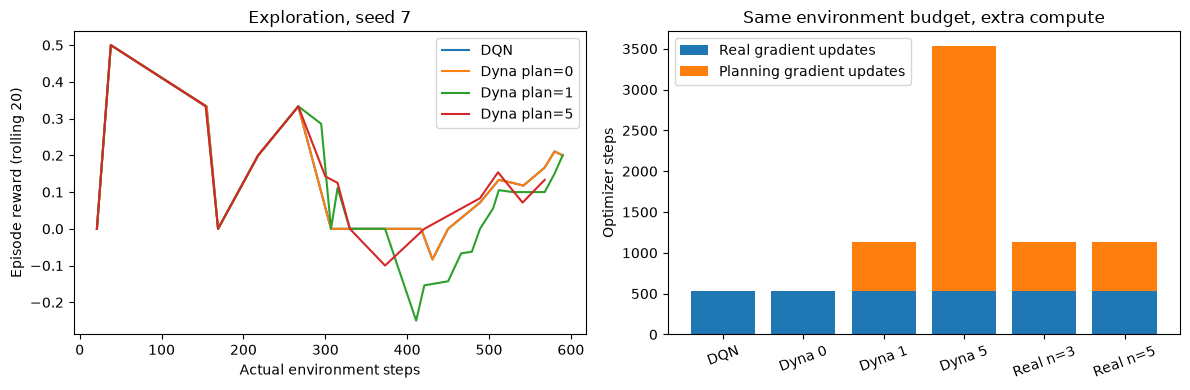

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in results_7[:4]:
    label = 'DQN' if r['baseline'] else f"Dyna plan={r['planning_steps']}"
    rewards = r['training_rewards']
    rolling = [np.mean(rewards[max(0, i-19):i+1]) for i in range(len(rewards))]
    axes[0].plot(np.cumsum(r['episode_lengths']), rolling, label=label)
axes[0].set(xlabel='Actual environment steps', ylabel='Episode reward (rolling 20)', title='Exploration, seed 7')
axes[0].legend()
labels = ['DQN', 'Dyna 0', 'Dyna 1', 'Dyna 5', 'Real n=3', 'Real n=5']
x = np.arange(len(labels))
axes[1].bar(x, [r['real_updates'] for r in results_7], label='Real gradient updates')
axes[1].bar(x, [r['planning_updates'] for r in results_7],
            bottom=[r['real_updates'] for r in results_7], label='Planning gradient updates')
axes[1].set(xticks=x, xticklabels=labels, ylabel='Optimizer steps', title='Same environment budget, extra compute')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend()
fig.tight_layout()
plt.show()

## 6. Greedy 평가와 DP 참조값

DP는 알려진 MDP 전체의 Bellman 기대값을 계산한다. Neural Q는 실제·가상 Batch로 학습한다.
목표 상태를 제외한 10개 상태에서 `max_a Q(s,a)`와 DP의 최적 V를 비교한다.
별도 Greedy 환경은 최장 20 Step이며 DP 최적 경로는 5 Step이다.
Network가 미관측 상태에도 값을 출력할 수 있다는 것과 World Model의 전이 일반화는 다른 문제다.

자연 종료 후의 Q 출력은 직접 학습하지 않아 목표 State에도 임의의 Neural 예측이 표시될 수 있다.
종료 Bootstrap Mask는 이 값에 의존하지 않으며, 목표 State는 RMSE 계산에서 제외한다.

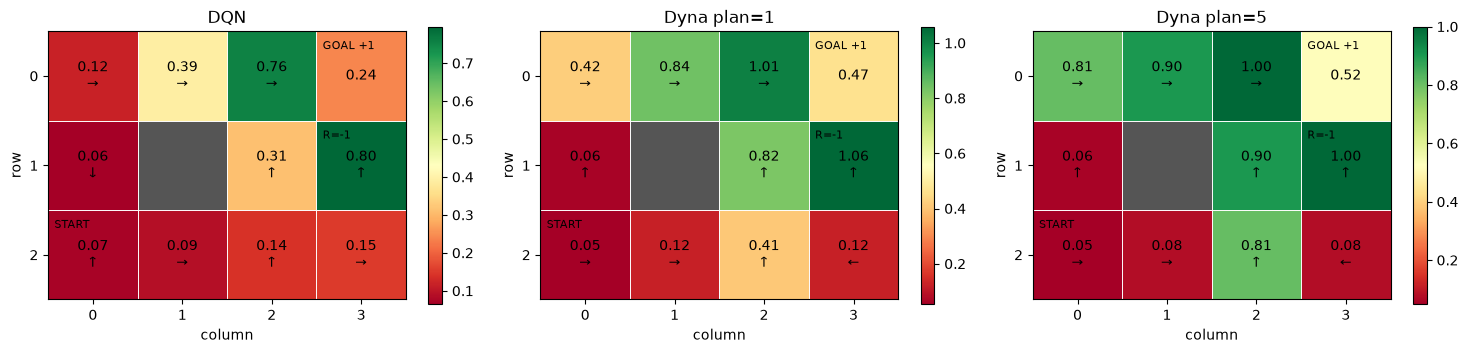

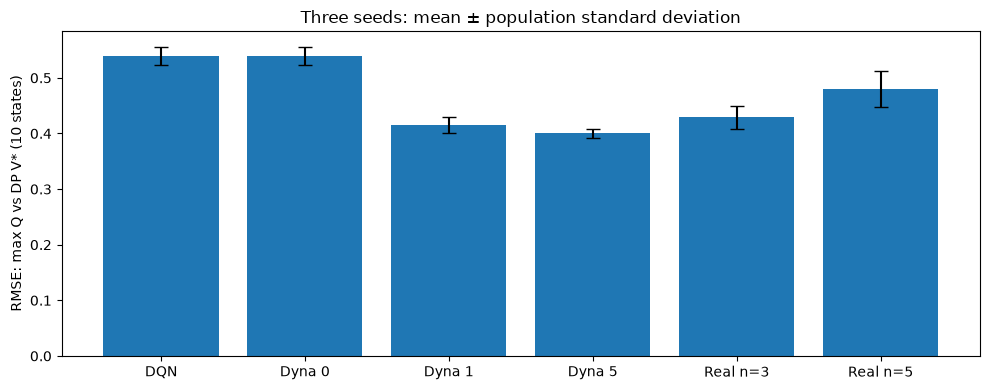

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axes, [results_7[0], results_7[2], results_7[3]]):
    q = r['q_values']
    policy = (q == q.max(-1, keepdims=True)).astype(float)
    policy /= policy.sum(-1, keepdims=True)
    title = 'DQN' if r['baseline'] else f"Dyna plan={r['planning_steps']}"
    plot_grid(q.max(-1), policy, title=title, ax=ax)
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
means, deviations = [], []
for index in range(6):
    values = [group[index]['max_q_rmse'] for group in [results_7, results_11, results_19]]
    means.append(np.mean(values))
    deviations.append(np.std(values))
ax.bar(labels, means, yerr=deviations, capsize=5)
ax.set(ylabel='RMSE: max Q vs DP V* (10 states)', title='Three seeds: mean ± population standard deviation')
fig.tight_layout()
plt.show()

## 7. Real n-step + Planning 1-step

$$Y^{real}=\sum_{k=0}^{m-1}\gamma^kR_{t+k+1}+\gamma^m(1-d)\max_aQ_{\bar\theta}(S_{t+m},a)$$

Window는 실제 전이만 받는다. `NStepExperience`는 시작 ID/행동, 보상합, 실제 m, 마지막 관측·flags·γ만 보유한다.
**Q Bootstrap은 저장하지 않으며 샘플을 학습할 때의 Target Network를 읽는다.** Planning은 항상 기존 1-step learn이다.

DQNLearner.learn은 외부 Target/Horizon을 받지 않으므로 n-step 함수에서 기존 Model·TD0·TDLoss·같은 Optimizer를
직접 조합한다. TD0의 γ에 앞서 continuation을 γ^(m−1)로 조정한다. 새로운 TargetGenerator나 Learner는 없다.

경계의 Planning 뒤 남은 Window를 실제 Horizon으로 Flush하여 Metadata Replay에 넣는다.
Flush 자체는 Gradient Step을 추가하지 않는다. 설정된 학습 주기를 따르며, 마지막 Flush 기록은
추가 Replay 학습을 하지 않으면 해당 실행에서 학습되지 않을 수 있다. raw Replay에는 실제 1-step 전이를 유지한다.

In [11]:
window = [Transition(0, 1, 1., 1, False, False).to_batch(),
          Transition(1, 0, 2., 1, False, False).to_batch(),
          Transition(1, 1, 3., 2, False, True).to_batch()]
record = make_n_step_experience(window, demo.target_generator, dtype=torch.float64)
print('n-step reward sum / actual horizon / truncated:', record.reward_sum.item(), record.horizon, record.truncated.item())
assert np.isclose(record.reward_sum.item(), 5.23)
assert not hasattr(record, 'bootstrap_value')
result = learn_real_n_step(demo, [record])
print('n-step TD Error / Loss:', result.td_error.tolist(), result.loss.item())
for r in results_7[2:3] + results_7[4:]:
    print('real n=', r['n'], '| planning n=1 | flush records=', r['flush_records'],
          '| metadata replay=', len(r['n_step_replay']), '| partial episode=', r['partial_episode'])

n-step reward sum / actual horizon / truncated: 5.23 3 True
n-step TD Error / Loss: [7.6033758193215295] 7.1033758193215295
real n= 1 | planning n=1 | flush records= 0 | metadata replay= 0 | partial episode= {'steps': 10, 'reward': 0.0}
real n= 3 | planning n=1 | flush records= 48 | metadata replay= 600 | partial episode= {'steps': 11, 'reward': 0.0}
real n= 5 | planning n=1 | flush records= 84 | metadata replay= 600 | partial episode= {'steps': 11, 'reward': 0.0}


## 8. 환경과 독립적인 Idle Planning

`plan`은 Environment나 ReplayBuffer를 받지 않으며 observe·step·행동 선택·ε 변경을 하지 않는다.
환경 render/RNG·Target·World는 유지하고 같은 Optimizer의 Step만 증가하는지 확인한다.
환경 Step 기준 Sync이므로 Idle Planning 중 자동 동기화하지 않는다. 필요하면 호출자가 명시적으로
`sync_target()`을 호출한다. Timer·Worker·비동기는 추가하지 않는다.

In [12]:
idle_env = make_dlfs4_gridworld_env(render_mode='ansi')
try:
    idle_env.reset(seed=7)
    environment_before = idle_env.render(), copy.deepcopy(idle_env.unwrapped.np_random.bit_generator.state)
    target_before = copy.deepcopy(demo.target_model.state_dict())
    behavior_before = torch.get_rng_state().clone()
    count_before = int(optimizer.state[demo.online_model.estimator.network.bias]['step'])
    idle = plan(world, demo, steps=10, batch_size=4, rng=np.random.default_rng(12))
    assert environment_before == (idle_env.render(), idle_env.unwrapped.np_random.bit_generator.state)
    assert torch.equal(behavior_before, torch.get_rng_state())
    assert all(torch.equal(value, demo.target_model.state_dict()[key]) for key, value in target_before.items())
    count_after = int(optimizer.state[demo.online_model.estimator.network.bias]['step'])
    print('Idle: env steps=0, observe=0, gradient steps=', idle['updates'], 'periodic syncs=0')
    print('Shared Adam step increment:', count_after - count_before, '| world pairs:', len(world))
finally:
    idle_env.close()

Idle: env steps=0, observe=0, gradient steps= 10 periodic syncs=0
Shared Adam step increment: 10 | world pairs: 1


## 9. Checkpoint와 구조 평가

- Model/Target/Optimizer는 공개 state_dict, World도 공개 state_dict로 저장한다. Planning·Behavior·Replay·n-step RNG,
  ε·카운터·주기·Pending Window·Metadata Replay를 함께 보존한다. 테스트는 같은 다음 Batch, Loss, Parameter,
  Optimizer 누적 상태, 후속 행동과 RNG의 정확한 재개를 확인한다.
- 기존 ReplayBuffer에 공개 checkpoint API는 없다. 테스트는 **현재 버전의 신뢰할 수 있는 Replay 객체**를
  torch.save/load(weights_only=False)로 보존한다. 장기 호환 checkpoint 형식이나 임의 파일 로드를 보장하지 않는다.
- 편의 run_steps는 live resume API가 아니다. 중간 Episode를 실제 환경까지 재개하려면 위치·환경 RNG·TimeLimit 경과 Step도 필요하다.
- Planning Sampler 교체는 예제의 작은 함수가 담당한다. 연속 상태 모델은 raw 관측 계약·Representation과 함께 재설계해야 한다.
- 우선순위 Planning은 TD Error와 샘플 ID 연결·우선순위 저장/추출이 필요하다. All-action은 predict(s,a) 같은 명시적 질의가 필요하다.
- 불확실성 기반 Q(σ)는 모델 불확실성·실행 시 σ·Target/Behavior 확률·경로 순서·경계·model version 등 추가 의미가 필요하다.
  이러한 연구 기능과 Neural World Model·자동 Scheduler는 이번 검증에 구현된 것이 아니다.

검증 범위와 최소 공통화 후보는 ARCHITECTURE.md에 기록한다. 라이브러리 본체와 공개 API는 변경하지 않는다.